#Importando e Conectando

In [164]:
from google.colab import drive

In [165]:
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [166]:
import pandas as pd

In [167]:
dados = pd.read_excel('/content/drive/MyDrive/Curso Análise de Dados - Eu ProgrAmo/Módulo 3/planilha_modulo3.xlsx')

In [168]:
dados.columns

Index(['Unnamed: 0', 'ID', 'IDADE', 'FAIXA IDADE', 'GENERO', 'COR/RACA/ETNIA',
       'PCD', 'EXPERIENCIA_PROFISSIONAL_PREJUDICADA', 'ASPECTOS_PREJUDICADOS',
       'VIVE_NO_BRASIL', 'ESTADO ONDE MORA', 'UF ONDE MORA',
       'REGIAO ONDE MORA', 'MUDOU DE ESTADO?', 'REGIAO DE ORIGEM',
       'NIVEL DE ENSINO', 'ÁREA DE FORMAÇÃO',
       'QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?', 'SETOR',
       'NUMERO DE FUNCIONARIOS', 'GESTOR?', 'CARGO COMO GESTOR', 'CARGO ATUAL',
       'NIVEL', 'FAIXA SALARIAL',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE TI/ENGENHARIA DE SOFTWARE VOCÊ TEVE ANTES DE COMEÇAR A TRABALHAR NA ÁREA DE DADOS?',
       'SALARIO'],
      dtype='object')

#Estatística Básica

In [169]:
import numpy as np

In [170]:
lista_idades = [45, 20, 37, 28, 24, 32, 25, 30, 34, 26, 45]

In [171]:
lista_idades

[45, 20, 37, 28, 24, 32, 25, 30, 34, 26, 45]

In [172]:
lista_idades.sort()
lista_idades

[20, 24, 25, 26, 28, 30, 32, 34, 37, 45, 45]

In [173]:
sum(lista_idades) #soma valores

346

In [174]:
len(lista_idades) #conta valores

11

In [175]:
sum(lista_idades) / len(lista_idades) #outro jeito de calcular media

31.454545454545453

In [176]:
print("Média idades: ", np.mean(lista_idades))

Média idades:  31.454545454545453


In [177]:
print("Mediana idades: ", np.median(lista_idades))

Mediana idades:  30.0


In [178]:
print("Desvio padrão idades: ", np.std(lista_idades))

Desvio padrão idades:  7.843510767317452


In [179]:
min(lista_idades)

20

In [180]:
max(lista_idades)

45

#### Voltando à Tabela de Dados

In [181]:
dados['IDADE'].mean() #média

np.float64(31.169168453657374)

In [182]:
dados['IDADE'].median() #mediana

30.0

In [183]:
dados['IDADE'].mode() #moda

,IDADE
0,27.0


In [184]:
dados['IDADE'].std() #desvio padrão

6.902802832143141

In [185]:
dados['IDADE'].min() #mínimo

18.0

In [186]:
dados['IDADE'].max() #máximo

54.0

In [187]:
dados[dados['GENERO']=="Feminino"]['IDADE'].mean() #média de idade de pessoas do genero feminino

np.float64(31.318051575931232)

In [188]:
dados[dados['GENERO']=='Masculino']['IDADE'].mean() #média de idade de pessoas do genero masculino

np.float64(31.147876077930373)

In [189]:
dados[dados['GENERO']=='Feminino']['SALARIO'].mean() #média salarial de pessoas do genero feminino

np.float64(8673.22460496614)

In [190]:
dados[dados['GENERO']=='Masculino']['SALARIO'].mean() #média salarial de pessoas do genero masculino

np.float64(11724.552688172043)

In [191]:
print("Média da Diferença Salarial: ", dados[dados['GENERO']=='Masculino']['SALARIO'].mean() - dados[dados['GENERO']=='Feminino']['SALARIO'].mean())

Média da Diferença Salarial:  3051.3280832059027


#Valores Faltantes

In [192]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4271 entries, 0 to 4270
Data columns (total 28 columns):
 #   Column                                                                                                                     Non-Null Count  Dtype  
---  ------                                                                                                                     --------------  -----  
 0   Unnamed: 0                                                                                                                 4271 non-null   int64  
 1   ID                                                                                                                         4271 non-null   object 
 2   IDADE                                                                                                                      4197 non-null   float64
 3   FAIXA IDADE                                                                                                                4271 

### Coluna de Gênero


In [193]:
dados.groupby('GENERO', dropna=False)['ID'].nunique() #dropna=False para de esconder os valores nulos

,ID
GENERO,
Feminino,1055
Masculino,3194
Prefiro não informar,12
NaN,9


In [194]:
dados['GENERO'] = dados['GENERO'].fillna("Prefiro não informar") #preenche os nulos e salva\atualiza em dados

In [195]:
dados.groupby('GENERO', dropna=False)['ID'].nunique() #dropna=False para de esconder os valores nulos

,ID
GENERO,
Feminino,1055
Masculino,3194
Prefiro não informar,21


### Coluna de Idade

In [196]:
dados[dados['IDADE'].isnull()]['FAIXA IDADE'].value_counts() #ver quantos preencheram faixa mas deixaram idade como nulo

,count
FAIXA IDADE,
55+,68
17-21,6


In [197]:
media17_21 = dados[dados['FAIXA IDADE']=='17-21']['IDADE'].mean() #pega média de idade de quem tem faixa 17-21
media17_21

np.float64(20.205479452054796)

In [198]:
dados.loc[(dados['FAIXA IDADE']=='17-21') & (dados['IDADE'].isnull()), 'IDADE'] #localiza dados que faixa é 17-21 E idade é nula

,IDADE
1925,NaN
2393,NaN
3367,NaN
4086,NaN
4177,NaN
4269,NaN


In [199]:
dados.loc[(dados['FAIXA IDADE']=='17-21') & (dados['IDADE'].isnull()), 'IDADE'] = media17_21 #atribui idade media (20) as idades nulas na faixa de 17-21

In [200]:
dados[dados['IDADE'].isnull()]['FAIXA IDADE'].value_counts()

,count
FAIXA IDADE,
55+,68


In [201]:
dados[dados['FAIXA IDADE']=='55+']['IDADE'] #todos que tem a faixa 55+ têm a idade nula, então não dá pra pegar a média

,IDADE
9,NaN
66,NaN
96,NaN
121,NaN
156,NaN
...,...
4001,NaN
4043,NaN
4048,NaN
4061,NaN


In [202]:
media_idade_geral = dados['IDADE'].mean() #pega a média de idade geral
media_idade_geral

np.float64(31.153517220250375)

In [203]:
dados.loc[(dados['FAIXA IDADE']=='55+') & (dados['IDADE'].isnull()), 'IDADE'] = media_idade_geral #atribui media(31) às idades nulas de faixa 55+

In [204]:
dados[dados['IDADE'].isnull()]['FAIXA IDADE'] #não tem mais idades nulas com faixa de idade

,FAIXA IDADE


### Coluna de Salário

In [205]:
dados[dados['SALARIO'].isnull()]['SALARIO'] #ver todos os salarios nulos

,SALARIO
12,NaN
28,NaN
34,NaN
39,NaN
63,NaN
...,...
4242,NaN
4252,NaN
4258,NaN
4260,NaN


In [206]:
mediana_salario = dados['SALARIO'].median() #mediana dos salarios, média não pois há muita discrepância salarial
mediana_salario

7625.5

In [207]:
dados.loc[dados['SALARIO'].isnull(), 'SALARIO'] = mediana_salario #localiza salarios nulos e atribui a mediana_salario

In [208]:
dados[dados['SALARIO'].isnull()]['SALARIO'] #não há mais salários nulos

,SALARIO


##Tabela Licitações

In [209]:
import chardet

with open('/content/drive/MyDrive/Curso Análise de Dados - Eu ProgrAmo/Módulo 4/licitacoes.csv', 'rb') as f:
    result = chardet.detect(f.read(10000))

print(result)

{'encoding': 'ISO-8859-1', 'confidence': 0.73, 'language': ''}


In [210]:
dados_lici = pd.read_csv(
    '/content/drive/MyDrive/Curso Análise de Dados - Eu ProgrAmo/Módulo 4/licitacoes.csv',
    encoding='ISO-8859-1',
    sep=';',
    on_bad_lines='skip'
)

In [211]:
dados_lici

,Número Licitação,Código UG,Nome UG,Código Modalidade Compra,Modalidade Compra,Número Processo,Objeto,Situação Licitação,Código Órgão Superior,Nome Órgão Superior,Código Órgão,Nome Órgão,UF,Município,Data Resultado Compra,Data Abertura,Valor Licitação
0,12016,160438,COMANDO 2 BRIGADA DE CAVALARIA MECANIZADA,-99,Pregão - Registro de Preço,80871182401201629,Objeto: Pregão Eletrônico - Aquisição de mater...,Evento de Resultado de Julgame,52000,Ministério da Defesa,52121,Comando do Exército,RS,URUGUAIANA,04/12/2018,17/08/2016,"18854,0000"
1,12017,160203,2º BATALHAO DE ENGENHARIA DE CONSTRUCAO,3,Concorrência,64040053530201713,Objeto: Contratação de empresa para construção...,Evento de Resultado de Julgame,52000,Ministério da Defesa,52121,Comando do Exército,PI,TERESINA,07/12/2018,NaN,"889571,4300"
2,12017,193002,DEPARTAMENTO NACIONAL DE OBRAS CONT.AS SECAS,2,Tomada de Preços,59400003079201636,Objeto: Contratação de empresa especializada n...,Evento de Resultado de Julgame,53000,Ministério da Integração e do Desenvolvime,22204,Departamento Nacional de Obras Contra as Seca,CE,FORTALEZA,07/12/2018,NaN,"865536,6500"
3,12018,925135,BANCO CENTRAL DO BRASIL - RECIFE,6,Dispensa de Licitação,148097,"Objeto: TV LED de 65 polegadas, UHD 4k, com co...",Encerrado,20101,Sem informação,25201,BANCO CENTRAL DO BRASIL-ORC.FISCAL/SEG.SOCIAL,-3,Inválido,04/12/2018,30/11/2018,"11075,9900"
4,12018,110101,GABINETE DA VICE-PRESIDENCIA DA REPUBLICA,7,Inexigibilidade de Licitação,00300000433201818,Objeto: Pretação de serviços de publicação de ...,Publicado,20000,Presidência da República,60000,Gabinete da Vice-Presidência da República,DF,BRASILIA,21/12/2018,NaN,"12000,0000"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15331,920182018,135023,EMBRAPA/CNPAB,-99,Pregão - Registro de Preço,21150000453201820,Objeto: Pregão Eletrônico - Contratar Empresa ...,Evento de Resultado de Julgame,22000,Ministério da Agricultura e Pecuária,22202,Empresa Brasileira de Pesquisa Agropecuária,RJ,SEROPEDICA,04/12/2018,26/11/2018,"2588060,0800"
15332,924192017,158274,INST.FED. FLUMINENSE/CAMPUS CAMPOS-CENTRO,6,Dispensa de Licitação,23318002419201784,Objeto: Retificação da dispensa de licitação n...,Publicado,26000,Ministério da Educação,26434,Instituto Federal Fluminense,RJ,CAMPOS DOS GOYTACAZES,26/12/2018,NaN,"490325,0000"
15333,990922018,158139,"INST.FED.DE EDUC.,CIENC.E TEC.FLUMINENSE",6,Dispensa de Licitação,23317009092201862,Objeto: Aquisição de material para revisão do ...,Encerrado,26000,Ministério da Educação,26434,Instituto Federal Fluminense,RJ,CAMPOS DOS GOYTACAZES,03/12/2018,NaN,"1149,7500"
15334,996252018,153035,UNIVERSIDADE FEDERAL DO TRIANGULO MINEIRO,6,Dispensa de Licitação,23085000625201811,Objeto: Pagamento da taxa referente ao primeir...,Encerrado,26000,Ministério da Educação,26254,Universidade Federal do Triângulo Mineiro,MG,UBERABA,04/12/2018,NaN,"298,0000"


In [212]:
dados_lici.columns

Index(['Número Licitação', 'Código UG', 'Nome UG', 'Código Modalidade Compra',
       'Modalidade Compra', 'Número Processo', 'Objeto', 'Situação Licitação',
       'Código Órgão Superior', 'Nome Órgão Superior', 'Código Órgão',
       'Nome Órgão', 'UF', 'Município', 'Data Resultado Compra',
       'Data Abertura', 'Valor Licitação'],
      dtype='object')

In [213]:
dados_lici.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15336 entries, 0 to 15335
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Número Licitação          15336 non-null  int64 
 1   Código UG                 15336 non-null  int64 
 2   Nome UG                   15336 non-null  object
 3   Código Modalidade Compra  15336 non-null  int64 
 4   Modalidade Compra         15336 non-null  object
 5   Número Processo           15336 non-null  object
 6   Objeto                    15336 non-null  object
 7   Situação Licitação        15336 non-null  object
 8   Código Órgão Superior     15336 non-null  int64 
 9   Nome Órgão Superior       15336 non-null  object
 10  Código Órgão              15336 non-null  int64 
 11  Nome Órgão                15336 non-null  object
 12  UF                        15336 non-null  object
 13  Município                 15336 non-null  object
 14  Data Resultado Compra 

In [214]:
dados_lici.groupby('Data Abertura', dropna=False)['Número Licitação'].nunique()

,Número Licitação
Data Abertura,
01/06/2018,1
01/10/2018,5
01/11/2018,27
01/12/2018,1
02/04/2018,1
...,...
31/07/2018,1
31/08/2018,1
31/10/2018,27


In [215]:
dados_lici['Data Abertura'] = pd.to_datetime(dados_lici['Data Abertura'], errors='coerce') #converte a coluna pra datetime

/tmp/ipykernel_2027/2320079279.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dados_lici['Data Abertura'] = pd.to_datetime(dados_lici['Data Abertura'], errors='coerce') #converte a coluna pra datetime


In [216]:
media_data = dados_lici['Data Abertura'].mean() #calcula media das datas
print(media_data)

2018-11-20 19:30:00


In [217]:
dados_lici['Data Abertura'] = dados_lici['Data Abertura'].fillna(media_data) #substitui datas nulas pela media

In [218]:
dados_lici.info() #sem mais valores faltantes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15336 entries, 0 to 15335
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Número Licitação          15336 non-null  int64         
 1   Código UG                 15336 non-null  int64         
 2   Nome UG                   15336 non-null  object        
 3   Código Modalidade Compra  15336 non-null  int64         
 4   Modalidade Compra         15336 non-null  object        
 5   Número Processo           15336 non-null  object        
 6   Objeto                    15336 non-null  object        
 7   Situação Licitação        15336 non-null  object        
 8   Código Órgão Superior     15336 non-null  int64         
 9   Nome Órgão Superior       15336 non-null  object        
 10  Código Órgão              15336 non-null  int64         
 11  Nome Órgão                15336 non-null  object        
 12  UF                

# Valores Discrepantes

In [219]:
import matplotlib.pyplot as plt

In [220]:
import numpy as np #de novo

####Exemplo com lista_idades

In [221]:
lista_idades = [20, 30, 25, 26, 21, 32, 19, 28, 25, 200]

In [222]:
media_listaidades = np.mean(lista_idades)
dp_listaidades = np.std(lista_idades)

In [223]:
print(media_listaidades) #dá uma média errada por conta do valor discrepante

42.6


In [224]:
print(dp_listaidades)  #desvio padrão muito alto

52.619768148481995


In [225]:
print(media_listaidades + 3*dp_listaidades) #o outlier (200) puxa o limite pra ele

200.45930444544598


In [226]:
print(media_listaidades - 3*dp_listaidades) #o outlier (200) estica e distorce, resultando em valores impossíveis (idade negativa)

-115.25930444544599


{'whiskers': [<matplotlib.lines.Line2D at 0x7ae7cf7a3410>,
 'caps': [<matplotlib.lines.Line2D at 0x7ae7cf7a39e0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7ae7d01c1880>],
 'medians': [<matplotlib.lines.Line2D at 0x7ae7cf7a24b0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7ae7cf77c110>],
 'means': []}

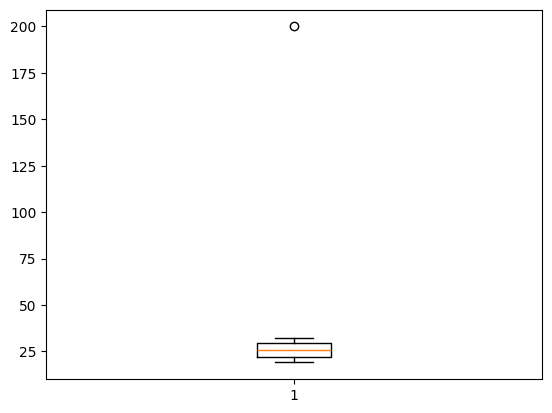

In [227]:
plt.boxplot(lista_idades)

*   Barra laranja: Mediana
*   Bordas: Quartis Q1 e Q3 - medianas das metades inferior e superior
*   Linhas: Limites inferior e superior
*   Círculo: Outlier




####Tabela Dados

In [228]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4271 entries, 0 to 4270
Data columns (total 28 columns):
 #   Column                                                                                                                     Non-Null Count  Dtype  
---  ------                                                                                                                     --------------  -----  
 0   Unnamed: 0                                                                                                                 4271 non-null   int64  
 1   ID                                                                                                                         4271 non-null   object 
 2   IDADE                                                                                                                      4271 non-null   float64
 3   FAIXA IDADE                                                                                                                4271 

{'whiskers': [<matplotlib.lines.Line2D at 0x7ae7cf7e6cc0>,
 'caps': [<matplotlib.lines.Line2D at 0x7ae7cf7e72c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7ae7cf7e6a20>],
 'medians': [<matplotlib.lines.Line2D at 0x7ae7cf7e7860>],
 'fliers': [<matplotlib.lines.Line2D at 0x7ae7cf7e7b30>],
 'means': []}

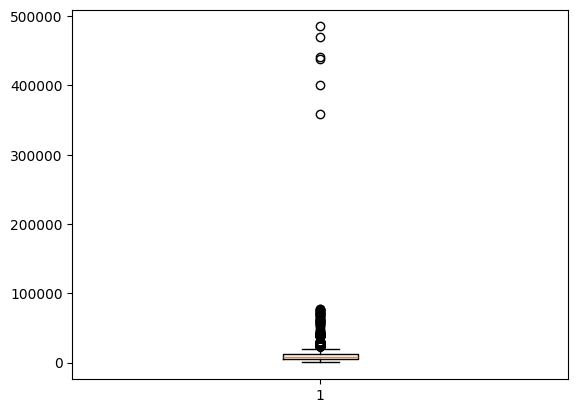

In [229]:
plt.boxplot(dados['SALARIO'])

{'whiskers': [<matplotlib.lines.Line2D at 0x7ae7cf642360>,
 'caps': [<matplotlib.lines.Line2D at 0x7ae7cf642900>,
 'boxes': [<matplotlib.lines.Line2D at 0x7ae7cf642060>],
 'medians': [<matplotlib.lines.Line2D at 0x7ae7cf642f30>],
 'fliers': [<matplotlib.lines.Line2D at 0x7ae7cf643200>],
 'means': []}

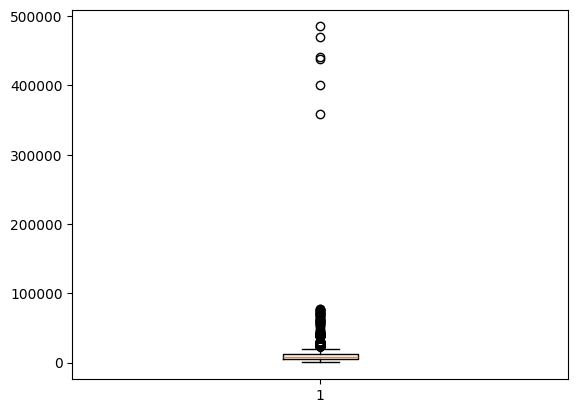

In [230]:
plt.boxplot(dados['SALARIO']) #.dropna() se estiver exibindo o gráfico vazio

In [231]:
Q1 = dados['SALARIO'].quantile(0.25) #quartil 1: mediana inferior (entre o limite inferior e a mediana)
print(Q1)

4751.5


In [232]:
Q3 = dados['SALARIO'].quantile(0.75) #quartil 3: mediana superior (entre o limite superior e a mediana)
print(Q3)

11794.5


In [233]:
IQR = Q3 - Q1 #interquartil: define o valor entre o Q1 e Q3, onde a maioria dos dados está concentrada
print(IQR)

7043.0


In [234]:
lim_superior = Q3 + (1.5 * IQR)
print(lim_superior)

22359.0


In [235]:
lim_inferior = Q1 - (1.5 * IQR)
print(lim_inferior)

-5813.0


In [236]:
dados['FAIXA SALARIAL'].value_counts()

,count
FAIXA SALARIAL,
de R$ 8.001/mês a R$ 12.000/mês,752
de R$ 4.001/mês a R$ 6.000/mês,584
de R$ 6.001/mês a R$ 8.000/mês,527
de R$ 12.001/mês a R$ 16.000/mês,437
de R$ 3.001/mês a R$ 4.000/mês,303
de R$ 2.001/mês a R$ 3.000/mês,285
de R$ 16.001/mês a R$ 20.000/mês,229
de R$ 1.001/mês a R$ 2.000/mês,216
de R$ 20.001/mês a R$ 25.000/mês,134


In [237]:
media_salario = dados['SALARIO'].mean()
print(media_salario)

10517.53348162023


In [238]:
dp_salario = dados['SALARIO'].std()
print(dp_salario)

18096.210989118474


In [239]:
limite_superior = media_salario + (3 * dp_salario) #3 pq os outliers estão muito dispersos
print(limite_superior) #regula o limite superior para ficar mais adequado ao desvio padrão

64806.16644897565


In [240]:
dados[dados['SALARIO']>limite_superior]['FAIXA SALARIAL'].value_counts() #mostra a faixa salarial de salarios que estão acima do limite

,count
FAIXA SALARIAL,
Acima de R$ 40.001/mês,19
de R$ 30.001/mês a R$ 40.000/mês,3


In [241]:
media_30_40 = dados[(dados['SALARIO']<limite_superior) & (dados['FAIXA SALARIAL']=="de R$ 30.001/mês a R$ 40.000/mês")]['SALARIO'].mean()
print(media_30_40) #calcula a média dos salários que estão dentro do limite E que a faixa salarial é 30-40

39002.19402985075


In [242]:
dados.loc[(dados['SALARIO']>limite_superior) & (dados['FAIXA SALARIAL']=="de R$ 30.001/mês a R$ 40.000/mês")]['SALARIO']
#localiza os 3 salários que estão na faixa salarial 30-40 mas estão fora do limite (provavelmente erro de digitação)

,SALARIO
2053,470454.0
2257,358966.0
3201,441190.0


In [243]:
dados.loc[(dados['SALARIO']>limite_superior) & (dados['FAIXA SALARIAL']=="de R$ 30.001/mês a R$ 40.000/mês"), 'SALARIO'] = media_30_40 #substitui esses valores pela media

In [244]:
dados[dados['SALARIO']>limite_superior]['FAIXA SALARIAL'].value_counts() #não mostra mais os 30-40 pois substituimos os outliers pela media dentro da faixa 30-40

,count
FAIXA SALARIAL,
Acima de R$ 40.001/mês,19


In [245]:
media_40 = dados[(dados['SALARIO']<limite_superior) & (dados['FAIXA SALARIAL']=="Acima de R$ 40.001/mês")]['SALARIO'].mean()
print(media_40) #calcula a média dos salários que estão dentro do limite e que a faixa é 30+

53127.846153846156


In [246]:
dados.loc[(dados['SALARIO']>limite_superior) & (dados['FAIXA SALARIAL']=="Acima de R$ 40.001/mês")]['SALARIO']
#localiza os salarios que estão acima do limite e com faixa 40+

,SALARIO
405,66592.0
443,71148.0
774,400212.0
1265,76740.0
2211,70040.0
2662,70088.0
2945,72164.0
2979,73217.0
3016,485191.0
3105,75272.0


In [247]:
dados.loc[(dados['SALARIO']>limite_superior) & (dados['FAIXA SALARIAL']=="Acima de R$ 40.001/mês"), 'SALARIO'] = media_40
#substitui os valores pela media dos valores dentro do limite

{'whiskers': [<matplotlib.lines.Line2D at 0x7ae7cf6d8110>,
 'caps': [<matplotlib.lines.Line2D at 0x7ae7cf6d8710>,
 'boxes': [<matplotlib.lines.Line2D at 0x7ae7d00c9880>],
 'medians': [<matplotlib.lines.Line2D at 0x7ae7cf6d8cb0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7ae7cf6d8f50>],
 'means': []}

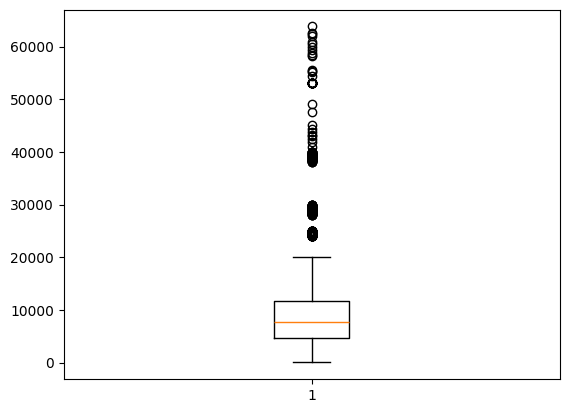

In [248]:
plt.boxplot(dados['SALARIO'].dropna())

os outliers estão mais controlados, no primeiro gráfico o máximo era 500000, nesse é 60000

##Intervalo de Confiança e Distribuição Amostral

In [249]:
from scipy import stats #importa módulo com funções de estatística

In [250]:
salarios = dados['SALARIO']
salarios

,SALARIO
0,11194.0
1,4695.0
2,14202.0
3,15463.0
4,7733.0
...,...
4266,4329.0
4267,3758.0
4268,19607.0
4269,989.0


In [251]:
media_amostral = np.mean(salarios) #média dos salários
print(media_amostral)

9904.390109813306


In [252]:
desvio_amostral = np.std(salarios)  #desvio padrão dos salários, quanto eles variam em relação à média
print(desvio_amostral)

8306.104872579343


In [253]:
nivel_confianca = 0.95 #95% de confiança

In [254]:
tamanho_amostra = len(salarios) #tamanho da amostra
print(tamanho_amostra)

4271


In [255]:
erro_padrao = stats.sem(salarios, nan_policy='omit') #o erro padrão é calculado dividindo o desvio padrão pela raiz quadrada do tamanho da amostra
print(erro_padrao)                                   #nan_policy='omit' tira os valores nulos

127.11109872023638


In [256]:
intervalo_confianca = stats.t.interval(nivel_confianca, tamanho_amostra-1, loc=media_amostral, scale=erro_padrao)
intervalo_confianca #estamos 95% confiantes de que a verdadeira média salarial da população está entre esses valores

(np.float64(9655.186295869078), np.float64(10153.593923757535))

#Featuring Engeneering

In [257]:
import numpy as np

In [258]:
dados.columns

Index(['Unnamed: 0', 'ID', 'IDADE', 'FAIXA IDADE', 'GENERO', 'COR/RACA/ETNIA',
       'PCD', 'EXPERIENCIA_PROFISSIONAL_PREJUDICADA', 'ASPECTOS_PREJUDICADOS',
       'VIVE_NO_BRASIL', 'ESTADO ONDE MORA', 'UF ONDE MORA',
       'REGIAO ONDE MORA', 'MUDOU DE ESTADO?', 'REGIAO DE ORIGEM',
       'NIVEL DE ENSINO', 'ÁREA DE FORMAÇÃO',
       'QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?', 'SETOR',
       'NUMERO DE FUNCIONARIOS', 'GESTOR?', 'CARGO COMO GESTOR', 'CARGO ATUAL',
       'NIVEL', 'FAIXA SALARIAL',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE TI/ENGENHARIA DE SOFTWARE VOCÊ TEVE ANTES DE COMEÇAR A TRABALHAR NA ÁREA DE DADOS?',
       'SALARIO'],
      dtype='object')

In [259]:
def preencher_nivel(gestor, nivel): #na coluna de nível não tem gestor, então vamos adicionar para as pessoas que marcaram gestor como verdadeiro
  if gestor == 1:
    return "Gestor"
  else:
    return nivel

In [260]:
dados['NOVO_NIVEL'] = dados.apply(lambda x: preencher_nivel(x['GESTOR?'], x['NIVEL']), axis=1)
#apply aplica na tabela dados
#lambda permite usar uma função anônima, sem ter que definir com def, já que só será usada agora
#x é o apelido da tabela dados
#axis=0 percorre colunas (verticalmente) e axis=1 percorre linhas (horizontalmente), nesse caso é 1 para acessar duas colunas por linha em cada registro

In [261]:
dados.groupby('NIVEL', dropna=False)['ID'].nunique()

,ID
NIVEL,
Júnior,1023
Pleno,1060
Sênior,898
NaN,1289


In [262]:
dados.groupby('NOVO_NIVEL', dropna=False)['ID'].nunique()

,ID
NOVO_NIVEL,
Gestor,712
Júnior,1023
Pleno,1060
Sênior,898
NaN,577


In [263]:
dados['NIVEL']

,NIVEL
0,Júnior
1,NaN
2,Pleno
3,Sênior
4,Pleno
...,...
4266,Pleno
4267,Pleno
4268,NaN
4269,Júnior


In [264]:
pd.get_dummies(dados, columns=['NIVEL']) #cria uma nova coluna booleana pra cada valor na coluna nível, como se fosse uma tabela verdade, ajuda a contar dados

,Unnamed: 0,ID,IDADE,FAIXA IDADE,GENERO,COR/RACA/ETNIA,PCD,EXPERIENCIA_PROFISSIONAL_PREJUDICADA,ASPECTOS_PREJUDICADOS,VIVE_NO_BRASIL,...,CARGO COMO GESTOR,CARGO ATUAL,FAIXA SALARIAL,QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?,QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE TI/ENGENHARIA DE SOFTWARE VOCÊ TEVE ANTES DE COMEÇAR A TRABALHAR NA ÁREA DE DADOS?,SALARIO,NOVO_NIVEL,NIVEL_Júnior,NIVEL_Pleno,NIVEL_Sênior
0,0,zzqzz3l9ily8nuo2m7wyzzqzz3w48o96,39.000000,35-39,Masculino,Parda,Não,Não acredito que minha experiência profissiona...,NaN,True,...,NaN,DBA/Administrador de Banco de Dados,de R$ 8.001/mês a R$ 12.000/mês,de 1 a 2 anos,de 7 a 10 anos,11194.0,Júnior,True,False,False
1,1,zzls2oftfn9law393oezzls2ofhvfpzd,32.000000,30-34,Masculino,Parda,Não,"Sim, acredito que a minha a experiência profis...",Aprovação em processos seletivos/entrevistas,True,...,Supervisor/Coordenador,NaN,de R$ 4.001/mês a R$ 6.000/mês,de 3 a 4 anos,Menos de 1 ano,4695.0,Gestor,False,False,False
2,2,zzdwqzfqqp1ypc7ps6m0hzzdwqz292yi,53.000000,50-54,Masculino,Branca,Não,NaN,NaN,True,...,NaN,Desenvolvedor/ Engenheiro de Software/ Analist...,de R$ 12.001/mês a R$ 16.000/mês,de 3 a 4 anos,Mais de 10 anos,14202.0,Pleno,False,True,False
3,3,zzbqh3uy7yk7k9qmkzzbqtb4s9faqspl,27.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,NaN,Cientista de Dados/Data Scientist,de R$ 12.001/mês a R$ 16.000/mês,de 4 a 6 anos,Não tive experiência na área de TI/Engenharia ...,15463.0,Sênior,False,False,True
4,4,zzaf1m95yan929rb94wzzaf1mekhvhpg,46.000000,45-49,Feminino,Branca,Não,Não acredito que minha experiência profissiona...,NaN,True,...,NaN,Desenvolvedor/ Engenheiro de Software/ Analist...,de R$ 6.001/mês a R$ 8.000/mês,Não tenho experiência na área de dados,Mais de 10 anos,7733.0,Pleno,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4266,4266,01jnrn9f6va0menfhk2ztm01jnrn96bp,26.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,NaN,Analista de Dados/Data Analyst,de R$ 4.001/mês a R$ 6.000/mês,de 3 a 4 anos,de 7 a 10 anos,4329.0,Pleno,False,True,False
4267,4267,01dyfxam4u4bi29fem01dyfxaq9akvqp,30.000000,30-34,Feminino,Branca,Não,Não acredito que minha experiência profissiona...,NaN,True,...,NaN,Engenheiro de Dados/Arquiteto de Dados/Data En...,de R$ 3.001/mês a R$ 4.000/mês,de 1 a 2 anos,Não tive experiência na área de TI/Engenharia ...,3758.0,Pleno,False,True,False
4268,4268,00zw9ks9d40z4u00zz3d20iix65qpli3,29.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,Gerente/Head,NaN,de R$ 16.001/mês a R$ 20.000/mês,de 4 a 6 anos,Não tive experiência na área de TI/Engenharia ...,19607.0,Gestor,False,False,False
4269,4269,00xu7yujd7s57emj00xu7y0c3njix3de,20.205479,17-21,Masculino,Branca,Não,NaN,NaN,True,...,NaN,Outra Opção,Menos de R$ 1.000/mês,Menos de 1 ano,Não tive experiência na área de TI/Engenharia ...,989.0,Júnior,True,False,False


In [265]:
def determinar_geracao(idade):
  if 13 < idade <=29:
    return "Geração Z"
  elif 29 < idade <= 39:
    return "Geração Y"
  elif 39 < idade <= 58:
    return "Geração X"
  else:
    return "Outra Geração"

In [266]:
dados['GERACAO'] = dados['IDADE'].apply(determinar_geracao) #nao precisa de lambda já q é só um argumento

In [267]:
dados['GERACAO'].value_counts()

,count
GERACAO,
Geração Z,1999
Geração Y,1761
Geração X,511


###Juntando planilhas

In [268]:
dados2 = pd.read_excel('/content/drive/MyDrive/Curso Análise de Dados - Eu ProgrAmo/Módulo 4/Planilha_Aula_parte2.xlsx')

In [269]:
dados.merge(dados2, on='ID', how='left') #junta planilhas baseado em uma coluna em comum (ID), deixando os dados da planilha dados na esquerda

,Unnamed: 0,ID,IDADE,FAIXA IDADE,GENERO,COR/RACA/ETNIA,PCD,EXPERIENCIA_PROFISSIONAL_PREJUDICADA,ASPECTOS_PREJUDICADOS,VIVE_NO_BRASIL,...,Qual o principal motivo da sua insatisfação com a empresa atual?,Você participou de entrevistas de emprego nos últimos 6 meses?,Você pretende mudar de emprego nos próximos 6 meses?,Quais os principais critérios que você leva em consideração no momento de decidir onde trabalhar?,Atualmente qual a sua forma de trabalho?,Qual a forma de trabalho ideal para você?,Caso sua empresa decida pelo modelo 100% presencial qual será sua atitude?,Sua empresa passu por Layoff em 2022?,Atuacao,Quais das linguagens listadas abaixo você utiliza no trabalho?
0,0,zzqzz3l9ily8nuo2m7wyzzqzz3w48o96,39.000000,35-39,Masculino,Parda,Não,Não acredito que minha experiência profissiona...,NaN,True,...,NaN,Não participei de entrevistas de emprego/proce...,Não estou buscando e não pretendo mudar de emp...,Benefícios,Modelo 100% presencial,Modelo híbrido com dias fixos de trabalho pres...,Vou aceitar e retornar ao modelo 100% presencial,Não ocorreram layoffs/demissões em massa na em...,Engenharia de Dados,SQL
1,1,zzls2oftfn9law393oezzls2ofhvfpzd,32.000000,30-34,Masculino,Parda,Não,"Sim, acredito que a minha a experiência profis...",Aprovação em processos seletivos/entrevistas,True,...,Falta de oportunidade de crescimento no empreg...,"Sim, fiz entrevistas mas não fui aprovado",Estou em busca de oportunidades dentro ou fora...,"Remuneração/Salário, Plano de carreira e oport...",Modelo 100% presencial,Modelo híbrido flexível (o funcionário tem lib...,Vou aceitar e retornar ao modelo 100% presencial,Não ocorreram layoffs/demissões em massa na em...,Gestor,NaN
2,2,zzdwqzfqqp1ypc7ps6m0hzzdwqz292yi,53.000000,50-54,Masculino,Branca,Não,NaN,NaN,True,...,Falta de oportunidade de crescimento no empreg...,Não participei de entrevistas de emprego/proce...,"Não estou buscando, mas me considero aberto a ...","Remuneração/Salário, Flexibilidade de trabalho...",Modelo híbrido com dias fixos de trabalho pres...,Modelo híbrido flexível (o funcionário tem lib...,Vou procurar outra oportunidade no modelo híbr...,Não ocorreram layoffs/demissões em massa na em...,desenvolve modelos preditivos e algoritmos de...,1
3,3,zzbqh3uy7yk7k9qmkzzbqtb4s9faqspl,27.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,NaN,"Sim, fui aprovado e mudei de emprego","Não estou buscando, mas me considero aberto a ...","Remuneração/Salário, Flexibilidade de trabalho...",Modelo híbrido flexível (o funcionário tem lib...,Modelo híbrido flexível (o funcionário tem lib...,Vou procurar outra oportunidade no modelo híbr...,Não ocorreram layoffs/demissões em massa na em...,desenvolve modelos preditivos e algoritmos de...,0
4,4,zzaf1m95yan929rb94wzzaf1mekhvhpg,46.000000,45-49,Feminino,Branca,Não,Não acredito que minha experiência profissiona...,NaN,True,...,Falta de oportunidade de crescimento no empreg...,Não participei de entrevistas de emprego/proce...,"Não estou buscando, mas me considero aberto a ...","Remuneração/Salário, Oportunidade de aprendiza...",Modelo 100% presencial,Modelo 100% presencial,Vou aceitar e retornar ao modelo 100% presencial,Não ocorreram layoffs/demissões em massa na em...,Outra atuação,SQL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4268,4266,01jnrn9f6va0menfhk2ztm01jnrn96bp,26.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,NaN,"Sim, fui aprovado e mudei de emprego",Não estou buscando e não pretendo mudar de emp...,"Remuneração/Salário, Benefícios, Flexibilidade...",Modelo 100% remoto,Modelo híbrido flexível (o funcionário tem lib...,Vou procurar outra oportunidade no modelo híbr...,Não ocorreram layoffs/demissões em massa na em...,Análise de Dados,SQL
4269,4267,01dyfxam4u4bi29fem01dyfxaq9akvqp,30.000000,30-34,Feminino,Branca,Não,Não acredito que minha experiência profissiona...,NaN,True,...,NaN,Não participei de entrevistas de emprego/proce...,Não estou buscando e não pretendo mudar de emp...,"Ambient

In [270]:
dados = dados.merge(dados2, on='ID', how='left') #coloca nova planilha dentro da planilha dados

In [271]:
dados.columns

Index(['Unnamed: 0', 'ID', 'IDADE', 'FAIXA IDADE', 'GENERO', 'COR/RACA/ETNIA',
       'PCD', 'EXPERIENCIA_PROFISSIONAL_PREJUDICADA', 'ASPECTOS_PREJUDICADOS',
       'VIVE_NO_BRASIL', 'ESTADO ONDE MORA', 'UF ONDE MORA',
       'REGIAO ONDE MORA', 'MUDOU DE ESTADO?', 'REGIAO DE ORIGEM',
       'NIVEL DE ENSINO', 'ÁREA DE FORMAÇÃO',
       'QUAL SUA SITUAÇÃO ATUAL DE TRABALHO?', 'SETOR',
       'NUMERO DE FUNCIONARIOS', 'GESTOR?', 'CARGO COMO GESTOR', 'CARGO ATUAL',
       'NIVEL', 'FAIXA SALARIAL',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE DADOS VOCÊ TEM?',
       'QUANTO TEMPO DE EXPERIÊNCIA NA ÁREA DE TI/ENGENHARIA DE SOFTWARE VOCÊ TEVE ANTES DE COMEÇAR A TRABALHAR NA ÁREA DE DADOS?',
       'SALARIO', 'NOVO_NIVEL', 'GERACAO',
       'Quanto tempo de experiência na área de dados você tem?',
       'Quanto tempo de experiência na área de TI/Engenharia de Software você teve antes de começar a trabalhar na área de dados?',
       'Você está satisfeito na sua empresa atual?',
       '

In [272]:
dados['Você pretende mudar de emprego nos próximos 6 meses?'].value_counts()

,count
Você pretende mudar de emprego nos próximos 6 meses?,
"Não estou buscando, mas me considero aberto a outras oportunidades",1354
Estou em busca de oportunidades dentro ou fora do Brasil,1011
Não estou buscando e não pretendo mudar de emprego nos próximos 6 meses,978
"Estou em busca de oportunidades, mas apenas fora do Brasil",353


In [273]:
dados['EM_BUSCA'] = dados['Você pretende mudar de emprego nos próximos 6 meses?'].str.contains('em busca', case=False) #case=False ignora case sensitive
dados['EM_BUSCA'].value_counts()

,count
EM_BUSCA,
False,2332
True,1364


In [274]:
dados['ABERTO_OPORTUNIDADES'] = dados['Você pretende mudar de emprego nos próximos 6 meses?'].str.contains('oportunidades', case=False)
dados['ABERTO_OPORTUNIDADES'].value_counts()

,count
ABERTO_OPORTUNIDADES,
True,2718
False,978


In [275]:
dados['COR/RACA/ETNIA'].value_counts()

,count
COR/RACA/ETNIA,
Branca,2746
Parda,1054
Preta,291
Amarela,128
Prefiro não informar,26
Outra,17
Indígena,11


In [276]:
dados['ETNIA_BRANCA'] = dados['COR/RACA/ETNIA'].str.contains('Branca', case=False)
dados['ETNIA_PARDA'] = dados['COR/RACA/ETNIA'].str.contains('Parda', case=False)
dados['ETNIA_PRETA'] = dados['COR/RACA/ETNIA'].str.contains('Preta', case=False)
dados['ETNIA_AMARELA'] = dados['COR/RACA/ETNIA'].str.contains('Amarela', case=False)
dados['ETNIA_INDIGENA'] = dados['COR/RACA/ETNIA'].str.contains('Indigena', case=False)
dados['ETNIA_OUTRA'] = dados['COR/RACA/ETNIA'].str.contains('Outra', case=False)
dados['ETNIA_PREFIRO_NAO_INFORMAR'] = dados['COR/RACA/ETNIA'].str.contains('Prefiro nao informar', case=False)

In [277]:
dados

,Unnamed: 0,ID,IDADE,FAIXA IDADE,GENERO,COR/RACA/ETNIA,PCD,EXPERIENCIA_PROFISSIONAL_PREJUDICADA,ASPECTOS_PREJUDICADOS,VIVE_NO_BRASIL,...,Quais das linguagens listadas abaixo você utiliza no trabalho?,EM_BUSCA,ABERTO_OPORTUNIDADES,ETNIA_BRANCA,ETNIA_PARDA,ETNIA_PRETA,ETNIA_AMARELA,ETNIA_INDIGENA,ETNIA_OUTRA,ETNIA_PREFIRO_NAO_INFORMAR
0,0,zzqzz3l9ily8nuo2m7wyzzqzz3w48o96,39.000000,35-39,Masculino,Parda,Não,Não acredito que minha experiência profissiona...,NaN,True,...,SQL,False,False,False,True,False,False,False,False,False
1,1,zzls2oftfn9law393oezzls2ofhvfpzd,32.000000,30-34,Masculino,Parda,Não,"Sim, acredito que a minha a experiência profis...",Aprovação em processos seletivos/entrevistas,True,...,NaN,True,True,False,True,False,False,False,False,False
2,2,zzdwqzfqqp1ypc7ps6m0hzzdwqz292yi,53.000000,50-54,Masculino,Branca,Não,NaN,NaN,True,...,1,False,True,True,False,False,False,False,False,False
3,3,zzbqh3uy7yk7k9qmkzzbqtb4s9faqspl,27.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,0,False,True,True,False,False,False,False,False,False
4,4,zzaf1m95yan929rb94wzzaf1mekhvhpg,46.000000,45-49,Feminino,Branca,Não,Não acredito que minha experiência profissiona...,NaN,True,...,SQL,False,True,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4268,4266,01jnrn9f6va0menfhk2ztm01jnrn96bp,26.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,SQL,False,False,True,False,False,False,False,False,False
4269,4267,01dyfxam4u4bi29fem01dyfxaq9akvqp,30.000000,30-34,Feminino,Branca,Não,Não acredito que minha experiência profissiona...,NaN,True,...,"SQL, Python",False,False,True,False,False,False,False,False,False
4270,4268,00zw9ks9d40z4u00zz3d20iix65qpli3,29.000000,25-29,Masculino,Branca,Não,NaN,NaN,True,...,NaN,False,True,True,False,False,False,False,False,False
4271,4269,00xu7yujd7s57emj00xu7y0c3njix3de,20.205479,17-21,Masculino,Branca,Não,NaN,NaN,True,...,"Python, SQL",True,True,True,False,False,False,False,False,False


#Correlação

In [278]:
correlacao_continua = dados['IDADE'].corr(dados['SALARIO']) # mais próximo de 1, correlação positiva, mais próximo de -1, correlação negativa
print(correlacao_continua) #conclusão: salário aumenta sim conforme a idade, mas muito pouco, quase neutro por estar mais próximo de 0

0.2902441968622099


In [279]:
import numpy as np

In [280]:
from scipy.stats import chi2_contingency

In [281]:
tabela_cruzada = pd.crosstab(dados['COR/RACA/ETNIA'], dados['NIVEL DE ENSINO'])
tabela_cruzada

NIVEL DE ENSINO,Doutorado ou Phd,Estudante de Graduação,Graduação/Bacharelado,Mestrado,Não tenho graduação formal,Prefiro não informar,Pós-graduação
COR/RACA/ETNIA,,,,,,,
Amarela,7,15,50,14,2,0,40
Branca,127,365,999,355,65,8,827
Indígena,0,2,4,2,0,0,3
Outra,0,0,6,3,1,0,7
Parda,50,178,333,113,33,3,344
Prefiro não informar,1,2,14,1,0,1,7
Preta,6,51,104,33,9,0,88


In [282]:
np.array(tabela_cruzada) #matriz

array([[  7,  15,  50,  14,   2,   0,  40],
       [127, 365, 999, 355,  65,   8, 827],
       [  0,   2,   4,   2,   0,   0,   3],
       [  0,   0,   6,   3,   1,   0,   7],
       [ 50, 178, 333, 113,  33,   3, 344],
       [  1,   2,  14,   1,   0,   1,   7],
       [  6,  51, 104,  33,   9,   0,  88]])

In [283]:
def cramer_coeficiente(col1, col2):
  tabela_cruzada = np.array(pd.crosstab(col1, col2))
  chi2 = chi2_contingency(tabela_cruzada)[0] #pega o primeiro
  soma = np.sum(tabela_cruzada)
  mini = min(tabela_cruzada.shape)-1
  cramer = np.sqrt(chi2/(soma * mini))
  return cramer

In [284]:
cramer_coeficiente(dados['COR/RACA/ETNIA'], dados['NIVEL DE ENSINO']) #conclusão: das pessoas analisadas, a etnia não teve grande impacto no nível de ensino

np.float64(0.04499106580480143)

In [285]:
cramer_coeficiente(dados['GENERO'], dados['NIVEL'])

np.float64(0.05408617389453069)

##Salvando planilha em csv

In [288]:
dados.to_csv('/content/drive/MyDrive/Curso Análise de Dados - Eu ProgrAmo/dados.csv', index=False)